**Data Manipulation and Analysis**                                                                           
1. Remove outliers from a car price dataset.


In [130]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

Loading the dataset

In [131]:
cars = pd.read_csv(r"C:\Users\BerniceBoateng\Desktop\machine-learning-zoomcamp\car_price_prediction.csv")
cars.head(3)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"


In [132]:
cars.shape

(4009, 12)

In [133]:
cars.describe()

,model_year
count,4009.000000
mean,2015.515590
std,6.104816
min,1974.000000
25%,2012.000000
50%,2017.000000
75%,2020.000000
max,2024.000000


In [134]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


In [135]:
cars.isnull().sum().sort_values(ascending=False)

clean_title     596
fuel_type       170
accident        113
brand             0
model             0
model_year        0
milage            0
engine            0
transmission      0
ext_col           0
int_col           0
price             0
dtype: int64

In [136]:
cars.duplicated().sum()

0

In [137]:
# changing the string columns to lower case
string_columns = cars.select_dtypes(include=['object']).columns
for col in string_columns:
    cars[col] = cars[col].str.lower()

cars.head(4)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,ford,utility police interceptor base,2013,"51,000 mi.",e85 flex fuel,300.0hp 3.7l v6 cylinder engine flex fuel capa...,6-speed a/t,black,black,at least 1 accident or damage reported,yes,"$10,300"
1,hyundai,palisade sel,2021,"34,742 mi.",gasoline,3.8l v6 24v gdi dohc,8-speed automatic,moonlight cloud,gray,at least 1 accident or damage reported,yes,"$38,005"
2,lexus,rx 350 rx 350,2022,"22,372 mi.",gasoline,3.5 liter dohc,automatic,blue,black,none reported,NaN,"$54,598"
3,infiniti,q50 hybrid sport,2015,"88,900 mi.",hybrid,354.0hp 3.5l v6 cylinder engine gas/electric h...,7-speed a/t,black,black,none reported,yes,"$15,500"


**Exploring the brand column**

In [138]:
cars['brand'].unique()

array(['ford', 'hyundai', 'lexus', 'infiniti', 'audi', 'acura', 'bmw',
       'tesla', 'land', 'aston', 'toyota', 'lincoln', 'jaguar',
       'mercedes-benz', 'dodge', 'nissan', 'genesis', 'chevrolet', 'kia',
       'jeep', 'bentley', 'honda', 'lucid', 'mini', 'porsche', 'hummer',
       'chrysler', 'volvo', 'cadillac', 'lamborghini', 'maserati',
       'volkswagen', 'subaru', 'rivian', 'gmc', 'ram', 'alfa', 'ferrari',
       'scion', 'mitsubishi', 'mazda', 'saturn', 'bugatti', 'polestar',
       'rolls-royce', 'mclaren', 'buick', 'lotus', 'pontiac', 'fiat',
       'karma', 'saab', 'mercury', 'plymouth', 'smart', 'maybach',
       'suzuki'], dtype=object)

In [139]:
cars['brand'].nunique()

57

In [140]:
cars['brand'].value_counts()

brand
ford             386
bmw              375
mercedes-benz    315
chevrolet        292
porsche          201
audi             200
toyota           199
lexus            163
jeep             143
land             130
nissan           116
cadillac         107
gmc               91
ram               91
dodge             90
tesla             87
kia               76
hyundai           72
mazda             64
acura             64
subaru            64
honda             63
volkswagen        59
infiniti          59
lincoln           52
jaguar            47
volvo             38
maserati          34
bentley           33
mini              33
buick             30
chrysler          28
lamborghini       26
mitsubishi        20
genesis           20
alfa              19
rivian            17
hummer            16
pontiac           15
ferrari           12
rolls-royce       11
aston              9
mclaren            6
scion              6
fiat               5
saturn             5
lotus              4
lucid  

In [141]:

brand_counts = cars['brand'].value_counts()
brand_threshold = 20
rare_brands = brand_counts[brand_counts < brand_threshold].index

cars.loc[cars['brand'].isin(rare_brands), 'brand'] = 'Other'
print("Number of unique brands before:", brand_counts.count()) 
print("Number of unique brands after:", cars['brand'].nunique())
cars['brand'].value_counts()

Number of unique brands before: 57
Number of unique brands after: 36


brand
ford             386
bmw              375
mercedes-benz    315
chevrolet        292
porsche          201
audi             200
toyota           199
lexus            163
jeep             143
Other            141
land             130
nissan           116
cadillac         107
gmc               91
ram               91
dodge             90
tesla             87
kia               76
hyundai           72
acura             64
mazda             64
subaru            64
honda             63
infiniti          59
volkswagen        59
lincoln           52
jaguar            47
volvo             38
maserati          34
bentley           33
mini              33
buick             30
chrysler          28
lamborghini       26
genesis           20
mitsubishi        20
Name: count, dtype: int64

**Exploring the model column**

In [142]:
cars['model'].unique()

array(['utility police interceptor base', 'palisade sel', 'rx 350 rx 350',
       ..., 'martin db7 vantage volante', 'impala 2lz', 'taycan'],
      dtype=object)

In [143]:
cars['model'].nunique()

1894

In [144]:
cars['model'].value_counts()

model
m3 base                    30
f-150 xlt                  24
corvette base              22
1500 laramie               18
wrangler sport             17
                           ..
g80 3.3t sport              1
xe 25t                      1
mc20 base                   1
911 carrera 4 cabriolet     1
taycan                      1
Name: count, Length: 1894, dtype: int64

In [145]:
# grouping the model names into base model names and 'other categories'
def get_first_word(model_name):
    return model_name.split(' ')[0]
cars['base_model'] = cars['model'].apply(get_first_word)

In [146]:
#checking the results
print("Number of unique models before:", cars['model'].nunique())
print("Number of unique models after:", cars['base_model'].nunique())
cars['base_model'].value_counts().head(3)

Number of unique models before: 1894
Number of unique models after: 517


base_model
rover    130
model     87
911       80
Name: count, dtype: int64

In [147]:
cars.head(2)

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,base_model
0,ford,utility police interceptor base,2013,"51,000 mi.",e85 flex fuel,300.0hp 3.7l v6 cylinder engine flex fuel capa...,6-speed a/t,black,black,at least 1 accident or damage reported,yes,"$10,300",utility
1,hyundai,palisade sel,2021,"34,742 mi.",gasoline,3.8l v6 24v gdi dohc,8-speed automatic,moonlight cloud,gray,at least 1 accident or damage reported,yes,"$38,005",palisade


In [148]:
model_counts = cars['base_model'].value_counts()
threshold = 20

rare_models = model_counts[model_counts < threshold].index
cars.loc[cars['base_model'].isin(rare_models), 'base_model'] = 'Other'

print("Final number of unique categories:", cars['base_model'].nunique())
cars['base_model'].value_counts()

Final number of unique categories: 43


base_model
Other          2350
rover           130
model            87
911              80
wrangler         73
f-150            64
corvette         61
mustang          61
amg              60
1500             56
f-250            47
silverado        46
e-class          46
escalade         45
camaro           45
suburban         38
x5               38
m3               37
expedition       34
rx               33
sierra           31
grand            31
cayenne          30
yukon            30
explorer         29
c-class          28
bronco           27
highlander       26
gx               26
s-class          25
4runner          25
tundra           25
sl-class         24
2500             24
challenger       24
q5               23
macan            23
tahoe            22
x6               22
continental      21
m4               21
panamera         21
sprinter         20
Name: count, dtype: int64

In [149]:
#dropping the original 'model' column
cars.drop(columns=['model'], inplace=True)
cars.head()

,brand,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,base_model
0,ford,2013,"51,000 mi.",e85 flex fuel,300.0hp 3.7l v6 cylinder engine flex fuel capa...,6-speed a/t,black,black,at least 1 accident or damage reported,yes,"$10,300",Other
1,hyundai,2021,"34,742 mi.",gasoline,3.8l v6 24v gdi dohc,8-speed automatic,moonlight cloud,gray,at least 1 accident or damage reported,yes,"$38,005",Other
2,lexus,2022,"22,372 mi.",gasoline,3.5 liter dohc,automatic,blue,black,none reported,NaN,"$54,598",rx
3,infiniti,2015,"88,900 mi.",hybrid,354.0hp 3.5l v6 cylinder engine gas/electric h...,7-speed a/t,black,black,none reported,yes,"$15,500",Other
4,audi,2021,"9,835 mi.",gasoline,2.0l i4 16v gdi dohc turbo,8-speed automatic,glacier white metallic,black,none reported,NaN,"$34,999",Other


**Exploring model year column**

In [150]:
cars['model_year'].unique()

array([2013, 2021, 2022, 2015, 2016, 2017, 2001, 2020, 2019, 2003, 2018,
       2023, 2000, 2006, 2011, 2012, 2007, 2014, 2005, 2009, 2010, 2004,
       2008, 1997, 1999, 1993, 2002, 1998, 2024, 1996, 1974, 1992, 1995,
       1994], dtype=int64)

In [151]:
cars['model_year'].nunique()

34

**Exploring the milage column**

In [152]:
cars['milage'].unique()

array(['51,000 mi.', '34,742 mi.', '22,372 mi.', ..., '53,705 mi.',
       '714 mi.', '2,116 mi.'], dtype=object)

In [153]:
cars['milage'].nunique()

2818

In [154]:
#renaming the 'milage' column to 'mileage'
cars.rename(columns={'milage': 'mileage'}, inplace=True)
cars.columns

Index(['brand', 'model_year', 'mileage', 'fuel_type', 'engine', 'transmission',
       'ext_col', 'int_col', 'accident', 'clean_title', 'price', 'base_model'],
      dtype='object')

In [155]:
#cleaning the mileage string
def clean_mileage(x):
    if isinstance(x, str):
        return x.replace('mi.', '').replace(',', '').strip()
    return x

cars['mileage'] = cars['mileage'].apply(clean_mileage)

#converting to integer
cars['mileage'] = cars['mileage'].astype(int)
cars['mileage'].head()

0    51000
1    34742
2    22372
3    88900
4     9835
Name: mileage, dtype: int32

In [156]:
#calculating Q1 (25%) and Q3 (75%)
Q1 = cars['mileage'].quantile(0.25)
Q3 = cars['mileage'].quantile(0.75)

#calculating the Interquartile Range (IQR)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 23044.0
Q3: 94100.0
IQR: 71056.0


In [157]:

#defining the bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)


Lower bound: -83540.0
Upper bound: 200684.0


In [158]:
print((cars['mileage'] >= upper_bound).sum())

69


In [159]:
#Filtering the data by keeping only the rows where mileage is between the lower and upper bounds
cars = cars[(cars['mileage'] >= lower_bound) & (cars['mileage'] <= upper_bound)]
print(f"Shape after removing outliers: {cars.shape}")

Shape after removing outliers: (3940, 12)


**Exploring the fuel_type column** 

In [160]:
cars['fuel_type'].unique()

array(['e85 flex fuel', 'gasoline', 'hybrid', nan, 'diesel',
       'plug-in hybrid', '–', 'not supported'], dtype=object)

In [161]:
cars['fuel_type'].nunique()

7

In [162]:
#replacing the "-" and "not supported" values with actual NaN 
cars['fuel_type'] = cars['fuel_type'].replace(['–', 'not supported'], np.nan)
cars['fuel_type'].unique()

array(['e85 flex fuel', 'gasoline', 'hybrid', nan, 'diesel',
       'plug-in hybrid'], dtype=object)

In [163]:
# finding the most common value (Mode)
most_common_fuel = cars['fuel_type'].mode()[0]
print("Most common fuel type:", most_common_fuel)


Most common fuel type: gasoline


In [164]:

# filling the missing values with that common type
cars['fuel_type'] = cars['fuel_type'].fillna(most_common_fuel)

#final Check - there should be no NaNs left
print("Missing values remaining:", cars['fuel_type'].isnull().sum())
cars['fuel_type'].unique()

Missing values remaining: 0


array(['e85 flex fuel', 'gasoline', 'hybrid', 'diesel', 'plug-in hybrid'],
      dtype=object)

**Exploring the engine column**

In [165]:
cars['engine'].unique()

array(['300.0hp 3.7l v6 cylinder engine flex fuel capability',
       '3.8l v6 24v gdi dohc', '3.5 liter dohc', ...,
       '136.0hp 1.8l 4 cylinder engine gasoline fuel',
       '270.0hp 2.0l 4 cylinder engine gasoline fuel',
       '420.0hp 5.9l 12 cylinder engine gasoline fuel'], dtype=object)

In [166]:
cars['engine'].nunique()

1125

In [167]:
import re

#extracting Horsepower (HP)
def extract_hp(engine_str):
    if isinstance(engine_str, str):
        match = re.search(r'(\d+\.?\d*)HP', engine_str, re.IGNORECASE)
        if match:
            return float(match.group(1))
    return np.nan



In [168]:
#extracting Displacement (Liters)
def extract_liters(engine_str):
    if isinstance(engine_str, str):
        match = re.search(r'(\d+\.?\d*)L', engine_str, re.IGNORECASE)
        if match:
            return float(match.group(1))
    return np.nan



In [169]:
# extracting Cylinders
def extract_cylinders(engine_str):
    if isinstance(engine_str, str):
        # Look for "V6", "V8" pattern
        match_v = re.search(r'V(\d+)', engine_str, re.IGNORECASE)
        if match_v:
            return int(match_v.group(1))
        
        # Look for "4 Cylinder", "6 Cylinder" pattern
        match_c = re.search(r'(\d+) Cylinder', engine_str, re.IGNORECASE)
        if match_c:
            return int(match_c.group(1))
            
    return np.nan



In [170]:
#apply them
cars['HP'] = cars['engine'].apply(extract_hp)
cars['Litres'] = cars['engine'].apply(extract_liters)
cars['Cylinders'] = cars['engine'].apply(extract_cylinders)

# Check how many are missing
print("Missing HP:", cars['HP'].isnull().sum())
print("Missing Litres:", cars['Litres'].isnull().sum())
print("Missing Cylinders:", cars['Cylinders'].isnull().sum())

Missing HP: 805
Missing Litres: 375
Missing Cylinders: 620


In [171]:
cars.head(3)

,brand,model_year,mileage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,base_model,HP,Litres,Cylinders
0,ford,2013,51000,e85 flex fuel,300.0hp 3.7l v6 cylinder engine flex fuel capa...,6-speed a/t,black,black,at least 1 accident or damage reported,yes,"$10,300",Other,300.0,3.7,6.0
1,hyundai,2021,34742,gasoline,3.8l v6 24v gdi dohc,8-speed automatic,moonlight cloud,gray,at least 1 accident or damage reported,yes,"$38,005",Other,NaN,3.8,6.0
2,lexus,2022,22372,gasoline,3.5 liter dohc,automatic,blue,black,none reported,NaN,"$54,598",rx,NaN,NaN,NaN


In [172]:
cars.drop(columns=['engine'], inplace=True)
cars.head(3)

,brand,model_year,mileage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,base_model,HP,Litres,Cylinders
0,ford,2013,51000,e85 flex fuel,6-speed a/t,black,black,at least 1 accident or damage reported,yes,"$10,300",Other,300.0,3.7,6.0
1,hyundai,2021,34742,gasoline,8-speed automatic,moonlight cloud,gray,at least 1 accident or damage reported,yes,"$38,005",Other,NaN,3.8,6.0
2,lexus,2022,22372,gasoline,automatic,blue,black,none reported,NaN,"$54,598",rx,NaN,NaN,NaN


In [173]:
print(cars['HP'].isnull().sum())
print(cars['Litres'].isnull().sum())
print(cars['Cylinders'].isnull().sum())

805
375
620


In [174]:
#filling the missing cylinders with the mode
cars['Cylinders']=cars['Cylinders'].fillna(cars['Cylinders'].mode()[0])

In [175]:
#filling the hp null values  with the mean based on the cylinders
cars['HP']=cars['HP'].fillna(cars.groupby('Cylinders')['HP'].transform('mean'))

In [176]:
#filling the litres null values  with the mean based on the cylinders
cars['Litres']=cars['Litres'].fillna(cars.groupby('Cylinders')['Litres'].transform('mean'))

In [177]:
#filling the missing cylinders with the mode
cars['Cylinders']=cars['Cylinders'].fillna(cars['Cylinders'].mode()[0])

In [178]:
print(cars['HP'].isnull().sum())
print(cars['Litres'].isnull().sum())
print(cars['Cylinders'].isnull().sum())

0
0
0


**Exploring the transmission column**

In [179]:
cars['transmission'].unique()

array(['6-speed a/t', '8-speed automatic', 'automatic', '7-speed a/t',
       'f', 'a/t', '8-speed a/t', 'transmission w/dual shift mode',
       '9-speed automatic', '6-speed m/t', '10-speed a/t', '9-speed a/t',
       '5-speed a/t', '1-speed a/t', 'automatic cvt',
       '7-speed automatic with auto-shift', 'cvt-f',
       '6-speed automatic with auto-shift', 'm/t', '10-speed automatic',
       'cvt transmission', '4-speed a/t', '6-speed automatic',
       '4-speed automatic', '7-speed m/t',
       '8-speed automatic with auto-shift', '5-speed automatic',
       '8-speed at', '1-speed automatic', '5-speed m/t', 'manual',
       '6-speed manual', 'variable', '2', '7-speed manual',
       'automatic, 9-spd 9g-tronic', 'automatic, 8-spd',
       'automatic, 8-spd sport w/sport & manual modes', '–',
       'auto, 6-spd w/cmdshft', 'transmission overdrive switch',
       '7-speed automatic', 'automatic, 8-spd pdk dual-clutch',
       'automatic, 8-spd m steptronic w/drivelogic, sport & ma

In [180]:
cars['transmission'].nunique()

61

In [181]:
def clean_transmission(transmission):
    if not isinstance(transmission, str):
        return np.nan
    
    t = transmission.lower()

    
    #automatic cars
    if 'a/t' in t or 'auto' in t or 'at' in t or 'fixed gear' in t or 'step' in t:
        return 'Automatic'
    
    #manual cars
    if 'm/t' in t or 'manual' in t or 'mt' in t:
        return 'Manual'
    
    #dual Clutch (often sporty automatics)
    if 'dual-clutch' in t or 'dct' in t or 'pdk' in t or 'dual shift' in t:
        return 'Dual Clutch'
    
     #cvt
    if 'cvt' in t or 'variable' in t:
        return 'CVT'
    
    #other cars
    if t in ['f', '2', '–', 'scheduled for or in production', 'transmission overdrive switch']:
        return np.nan
        
    return 'Other'

In [182]:
cars['transmission'] = cars['transmission'].apply(clean_transmission)
cars['transmission'].value_counts()
cars['transmission'].unique()

array(['Automatic', nan, 'Dual Clutch', 'Manual', 'CVT', 'Other'],
      dtype=object)

In [183]:
print("Missing car transmission:", cars['transmission'].isnull().sum())

Missing car transmission: 17


In [184]:
#filling missing transmission with the mode
mode_transmission = cars['transmission'].mode()[0]
cars['transmission'] = cars['transmission'].fillna(mode_transmission)
cars['transmission'].value_counts()

transmission
Automatic      3110
Dual Clutch     397
Manual          365
CVT              66
Other             2
Name: count, dtype: int64

In [185]:
#changing the the other to the mode which is autommatic
cars['transmission'] = cars['transmission'].replace('Other', 'Automatic')
cars['transmission'].value_counts()

transmission
Automatic      3112
Dual Clutch     397
Manual          365
CVT              66
Name: count, dtype: int64

In [186]:
cars.head(3)

,brand,model_year,mileage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,base_model,HP,Litres,Cylinders
0,ford,2013,51000,e85 flex fuel,Automatic,black,black,at least 1 accident or damage reported,yes,"$10,300",Other,300.000000,3.70000,6.0
1,hyundai,2021,34742,gasoline,Automatic,moonlight cloud,gray,at least 1 accident or damage reported,yes,"$38,005",Other,332.022305,3.80000,6.0
2,lexus,2022,22372,gasoline,Automatic,blue,black,none reported,NaN,"$54,598",rx,332.022305,3.27034,6.0


**Exploring the exterior color column**

In [187]:
cars['ext_col'].unique()

array(['black', 'moonlight cloud', 'blue', 'glacier white metallic',
       'silver', 'fuji white', 'yellow', 'white', 'gray', 'purple',
       'green', 'iconic silver metallic', 'mythos black metallic', 'red',
       'gold', 'lunar silver metallic', 'mountain air metallic',
       'caspian blue', 'tango red metallic', '–', 'alpine white',
       'blu eleos', 'horizon blue', 'granite crystal clearcoat metallic',
       'orange', 'beige', 'rift metallic', 'atomic silver',
       'summit white', 'imperial blue metallic',
       'magnetic gray clearcoat', 'bright white clearcoat',
       'typhoon gray', 'crystal black silica', 'arctic gray metallic',
       'selenite grey metallic', 'ultra black', 'lunare white metallic',
       'hyper red', 'daytona gray pearl effect', 'vik black',
       'pacific blue metallic', 'obsidian black metallic',
       'silver ice metallic', 'sonic silver metallic', 'nightfall mica',
       'apex blue', 'go mango!', 'ingot silver metallic',
       'midnight bl

In [188]:
cars['ext_col'].nunique()

317

In [189]:
import numpy as np

def clean_ext_col(color):
    if not isinstance(color, str):
        return np.nan
    
    c = color.lower().strip()
    
    #other values
    if c in ['–', '-', 'c / c', 'unknown', 'n/a']:
        return np.nan

    #strong base colors 
    if any(x in c for x in [
        'black', 'ebony', 'obsidian', 'midnight', 'ultra black', 
        'vik black', 'crystal black', 'beluga'
    ]):
        return 'Black'
    
    if any(x in c for x in [
        'white', 'alpine', 'fuji', 'summit', 'glacier', 'ibis', 
        'quartz', 'yulong', 'bright white', 'wind chill'
    ]):
        return 'White'
    
    if any(x in c for x in [
        'silver', 'iconic silver', 'atomic silver', 'lunar silver',
        'sonic silver', 'reflex silver', 'indus silver', 'ingot'
    ]):
        return 'Silver'
    
    if any(x in c for x in [
        'gray', 'grey', 'granite', 'magnetic', 'arctic', 'thunder',
        'daytona', 'donington', 'carpathian', 'selenite',
        'eiger', 'nightfall', 'quartzite'
    ]):
        return 'Gray'

    #remaining standard colors
    if any(x in c for x in ['blue', 'blu', 'navy', 'pacific', 'apex', 'phytonic']):
        return 'Blue'
    
    if any(x in c for x in ['red', 'ruby', 'tango', 'infrared', 'rapid', 'matador']):
        return 'Red'
    
    if any(x in c for x in ['green', 'verde', 'jungle']):
        return 'Green'
    
    if 'yellow' in c:
        return 'Yellow'
    
    if any(x in c for x in ['orange', 'mango']):
        return 'Orange'
    
    if 'purple' in c:
        return 'Purple'
    
    if 'brown' in c:
        return 'Brown'
    
    if 'beige' in c:
        return 'Beige'
    
    if 'gold' in c:
        return 'Gold'

    #fallback
    return 'Other'


In [190]:
cars['ext_col'] = cars['ext_col'].apply(clean_ext_col)

print(cars['ext_col'].value_counts())
print("Missing values:", cars['ext_col'].isnull().sum())

ext_col
Black     1005
White      916
Gray       551
Silver     410
Blue       391
Red        305
Green       78
Other       65
Brown       44
Gold        41
Orange      38
Beige       38
Yellow      30
Purple      12
Name: count, dtype: int64
Missing values: 16


In [191]:
#filled missing values with the most common color (Mode)
mode_color = cars['ext_col'].mode()[0]
cars['ext_col'] = cars['ext_col'].fillna(mode_color)

print("Final unique colors:", cars['ext_col'].unique())
print("missing colors:", cars['ext_col'].isnull().sum())

Final unique colors: ['Black' 'Other' 'Blue' 'White' 'Silver' 'Yellow' 'Gray' 'Purple' 'Green'
 'Red' 'Gold' 'Orange' 'Beige' 'Brown']
missing colors: 0


**Exploring the interior column**

In [192]:
cars['int_col'].unique()

array(['black', 'gray', 'ebony.', 'pimento / ebony', 'brown', 'white',
       '–', 'beige', 'jet black', 'light gray', 'anthracite', 'red',
       'nero ade', 'blue', 'charcoal', 'green', 'rioja red',
       'canberra beige/black', 'roast', 'ivory / ebony',
       'silk beige/black', 'medium pewter', 'ice', 'black / express red',
       'obsidian black', 'ebony', 'orange', 'caramel', 'orchid',
       'graphite', 'tan/ebony', 'cappuccino', 'nero', 'sahara tan',
       'hotspur', 'blk', 'black onyx', 'nougat brown', 'titan black',
       'oyster w/contrast', 'silver', 'macchiato beige/black',
       'sand beige', 'navy pier', 'parchment.', 'sarder brown',
       'grace white', 'cloud', 'espresso', 'mesa', 'whisper beige',
       'medium dark slate', 'gold', 'camel leather', 'tupelo',
       'black/red', 'parchment', 'beluga hide', 'charles blue',
       'global black', 'titan black / quarzit', 'mocha', 'portland',
       'medium light camel', 'black / saddle', 'ash', 'ebony / pimento',
 

In [193]:
cars['int_col'].nunique()

152

In [194]:
import numpy as np
import re

def clean_int_col(color):
    if not isinstance(color, str):
        return np.nan
    
    # normalize
    c = color.lower()
    c = re.sub(r'[^\w\s/]', '', c)  # remove dots, commas, etc.

    #other
    if c.strip() in ['–', '-', 'unknown', 'n/a']:
        return np.nan

    #black
    if any(x in c for x in [
        'black', 'ebony', 'nero', 'jet black', 'onyx', 'carbon',
        'global black', 'titan black', 'satin black', 'amg black',
        'beluga', 'charcoal black'
    ]):
        return 'Black'

    #gray 
    if any(x in c for x in [
        'gray', 'grey', 'graphite', 'anthracite', 'slate', 'ash',
        'stone', 'pewter', 'shale', 'porpoise', 'rock gray'
    ]):
        return 'Gray'

    # beige / tan 
    if any(x in c for x in [
        'beige', 'ivory', 'parchment', 'linen', 'camel', 'sand',
        'cashmere', 'almond', 'oyster', 'champagne'
    ]):
        return 'Beige'

    #brown
    if any(x in c for x in [
        'brown', 'espresso', 'mocha', 'walnut', 'chestnut',
        'cappuccino', 'caramel', 'brandy', 'saddle'
    ]):
        return 'Brown'

    # WHITE
    if 'white' in c:
        return 'White'

    # RED
    if any(x in c for x in [
        'red', 'pimento', 'rioja', 'garnet', 'magma',
        'adrenaline', 'classic red'
    ]):
        return 'Red'

    # BLUE
    if any(x in c for x in [
        'blue', 'navy', 'cobalt', 'rhapsody', 'charles blue'
    ]):
        return 'Blue'

    # GREEN
    if any(x in c for x in [
        'green', 'agave', 'cypress'
    ]):
        return 'Green'

    #orange
    if 'orange' in c:
        return 'Orange'
    if 'yellow' in c:
        return 'Yellow'

    return 'Other'


In [195]:
cars['int_col'] = cars['int_col'].apply(clean_int_col)

print(cars['int_col'].value_counts())
print("Missing values:", cars['int_col'].isnull().sum())


int_col
Black     2207
Beige      541
Gray       487
Other      201
Brown      174
Red        134
White      129
Blue        34
Orange      23
Green        8
Yellow       2
Name: count, dtype: int64
Missing values: 0


In [196]:
#filled missing values with the most common color (Mode)
mode_color = cars['int_col'].mode()[0]
cars['int_col'] = cars['int_col'].fillna(mode_color)

print("Final unique colors:", cars['int_col'].unique())
print("missing colors:", cars['int_col'].isnull().sum())

Final unique colors: ['Black' 'Gray' 'Brown' 'White' 'Other' 'Beige' 'Red' 'Blue' 'Green'
 'Orange' 'Yellow']
missing colors: 0


In [197]:
cars.head(2)

,brand,model_year,mileage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,base_model,HP,Litres,Cylinders
0,ford,2013,51000,e85 flex fuel,Automatic,Black,Black,at least 1 accident or damage reported,yes,"$10,300",Other,300.000000,3.7,6.0
1,hyundai,2021,34742,gasoline,Automatic,Other,Gray,at least 1 accident or damage reported,yes,"$38,005",Other,332.022305,3.8,6.0


**Exploring the accident column**

In [198]:
cars['accident'].unique()

array(['at least 1 accident or damage reported', 'none reported', nan],
      dtype=object)

In [199]:
cars['accident'].nunique()

2

In [200]:
print(cars['accident'].value_counts())
print("Missing values:", cars['accident'].isnull().sum())

accident
none reported                             2876
at least 1 accident or damage reported     953
Name: count, dtype: int64
Missing values: 111


In [201]:
#fillingthe null values with non reported
cars['accident'] = cars['accident'].fillna('none reported')

cars['accident'] = cars['accident'].replace({
    'at least 1 accident or damage reported': 'Accident',
    'none reported': 'None'
})

cars['accident'].value_counts()

accident
None        2987
Accident     953
Name: count, dtype: int64

**Exploring the clean title column**

In [202]:
cars['clean_title'].unique()

array(['yes', nan], dtype=object)

In [203]:
cars['clean_title'].nunique()

1

In [204]:
cars['clean_title'].value_counts()

clean_title
yes    3346
Name: count, dtype: int64

In [208]:
cars['clean_title'].isnull().sum()  

594

In [209]:
#since the only value for the clean_tile is yes and nun i think all the nun is no
cars['clean_title'] = cars['clean_title'].fillna('no')
cars['clean_title'].value_counts()

clean_title
yes    3346
no      594
Name: count, dtype: int64

**Exploring the price column**

In [211]:
cars['price'].unique()

array(['$10,300', '$38,005', '$54,598', ..., '$59,335', '$349,950',
       '$90,998'], dtype=object)

In [212]:
cars['price'].isnull().sum()

0

In [213]:
#cleaning the text and converting to interger
cars['price'] = cars['price'].astype(str).str.replace('$', '').str.replace(',', '')
cars['price'] = cars['price'].astype(int)


In [214]:
#identifying outlier
Q1 = cars['price'].quantile(0.25)
Q3 = cars['price'].quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)  

Q1: 17899.75
Q3: 49999.0
IQR: 32099.25


In [215]:
#identifying lower and upper bound
lower_bound= Q1 - 1.5 * IQR
upper_bound= Q3 + 1.5 * IQR
print("Lower bound:", lower_bound)  
print("Upper bound:", upper_bound)


Lower bound: -30249.125
Upper bound: 98147.875


In [216]:
print((cars['price'] >= upper_bound).sum())

251


In [217]:
#filtering the data
original_shape = cars.shape
cars = cars[(cars['price'] >= lower_bound) & (cars['price'] <= upper_bound)]
print(f"Rows removed: {original_shape[0] - cars.shape[0]}")
print(f"Final shape: {cars.shape}")

Rows removed: 251
Final shape: (3689, 14)


**Final preprocessed dataset**

In [218]:
cars.head(3)

,brand,model_year,mileage,fuel_type,transmission,ext_col,int_col,accident,clean_title,price,base_model,HP,Litres,Cylinders
0,ford,2013,51000,e85 flex fuel,Automatic,Black,Black,Accident,yes,10300,Other,300.000000,3.70000,6.0
1,hyundai,2021,34742,gasoline,Automatic,Other,Gray,Accident,yes,38005,Other,332.022305,3.80000,6.0
2,lexus,2022,22372,gasoline,Automatic,Blue,Black,None,no,54598,rx,332.022305,3.27034,6.0


In [219]:
cars.shape

(3689, 14)

In [220]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3689 entries, 0 to 4008
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         3689 non-null   object 
 1   model_year    3689 non-null   int64  
 2   mileage       3689 non-null   int32  
 3   fuel_type     3689 non-null   object 
 4   transmission  3689 non-null   object 
 5   ext_col       3689 non-null   object 
 6   int_col       3689 non-null   object 
 7   accident      3689 non-null   object 
 8   clean_title   3689 non-null   object 
 9   price         3689 non-null   int32  
 10  base_model    3689 non-null   object 
 11  HP            3689 non-null   float64
 12  Litres        3689 non-null   float64
 13  Cylinders     3689 non-null   float64
dtypes: float64(3), int32(2), int64(1), object(8)
memory usage: 403.5+ KB


In [221]:
cars.describe()

,model_year,mileage,price,HP,Litres,Cylinders
count,3689.000000,3689.000000,3689.000000,3689.000000,3689.000000,3689.000000
mean,2015.433722,65001.210897,33823.781242,328.191177,3.611507,6.182434
std,5.965738,46711.663176,21142.685730,105.209647,1.357132,1.462494
min,1992.000000,100.000000,2000.000000,70.000000,0.650000,3.000000
25%,2012.000000,26269.000000,17000.000000,265.000000,2.500000,6.000000
50%,2017.000000,56000.000000,29995.000000,332.022305,3.400000,6.000000
75%,2020.000000,94650.000000,45950.000000,385.000000,4.400000,8.000000
max,2024.000000,200000.000000,98000.000000,1020.000000,8.300000,12.000000


In [222]:
cars.isnull().sum()

brand           0
model_year      0
mileage         0
fuel_type       0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
base_model      0
HP              0
Litres          0
Cylinders       0
dtype: int64

In [224]:
cars.duplicated().sum()

0

2. Complete the data analysis and visualization for the car price dataset. Submit a report
detailing your findings, visualizations, and any insights derived from the data.

**Analyzing the target to see see the distribution of car prices**

In [226]:
import matplotlib.pyplot as plt 
import seaborn as sns 
sns.set_style("whitegrid")
plt.figure(figsize=(10,6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

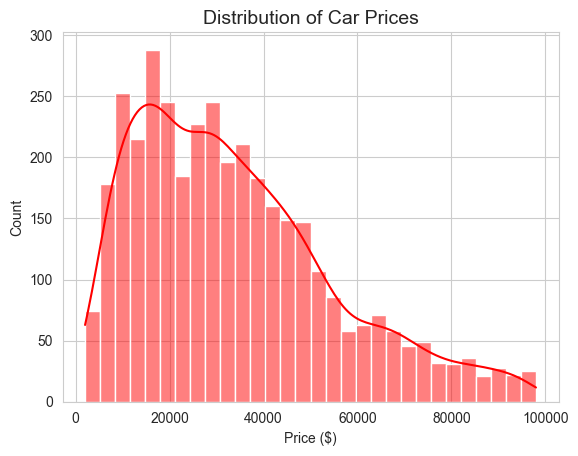

In [228]:
#Histogram
sns.histplot(cars['price'],kde=True, color = 'red' ,bins =30)
plt.title('Distribution of Car Prices', fontsize = 14)
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.show()

**Numerical Correlation**

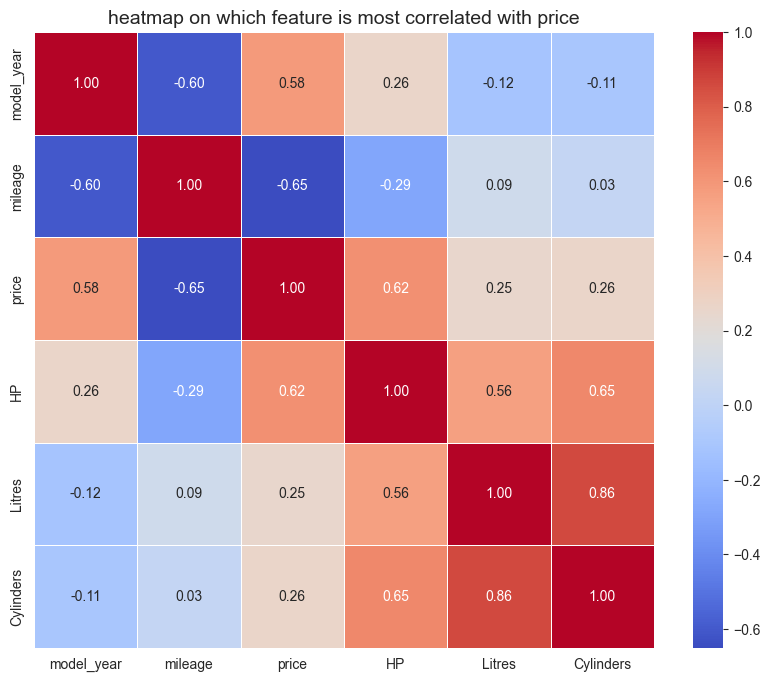

In [230]:
numeric_cars = cars.select_dtypes(include=['int32', 'int64', 'float64'])

#calculating the correlation matrix
corr = numeric_cars.corr()

#plotting the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('heatmap on which feature is most correlated with price', fontsize=14)
plt.show()

**Brand vs Price:**

C:\Users\BerniceBoateng\AppData\Local\Temp\ipykernel_8796\2096681624.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cars_top_brands, x='brand', y='price', palette='viridis')


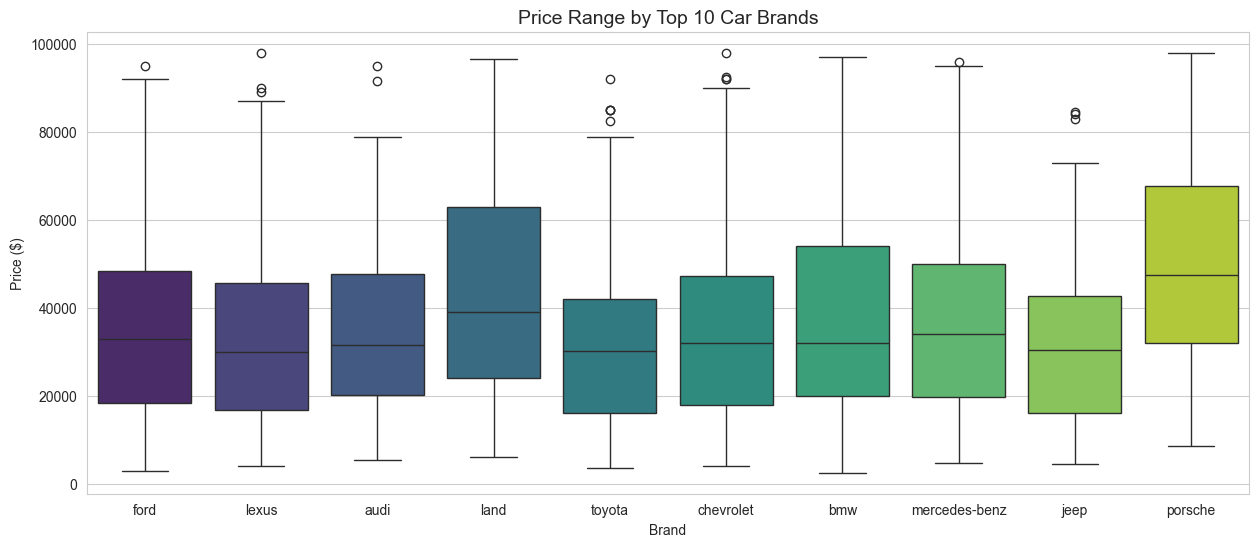

In [231]:
top_brands = cars['brand'].value_counts().nlargest(10).index
cars_top_brands = cars[cars['brand'].isin(top_brands)]
plt.figure(figsize=(15, 6))
sns.boxplot(data=cars_top_brands, x='brand', y='price', palette='viridis')
plt.title('Price Range by Top 10 Car Brands', fontsize=14)
plt.ylabel('Price ($)')
plt.xlabel('Brand')
plt.show()


**Transmission vs Price**


C:\Users\BerniceBoateng\AppData\Local\Temp\ipykernel_8796\628076039.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cars, x='transmission', y='price', palette='coolwarm')


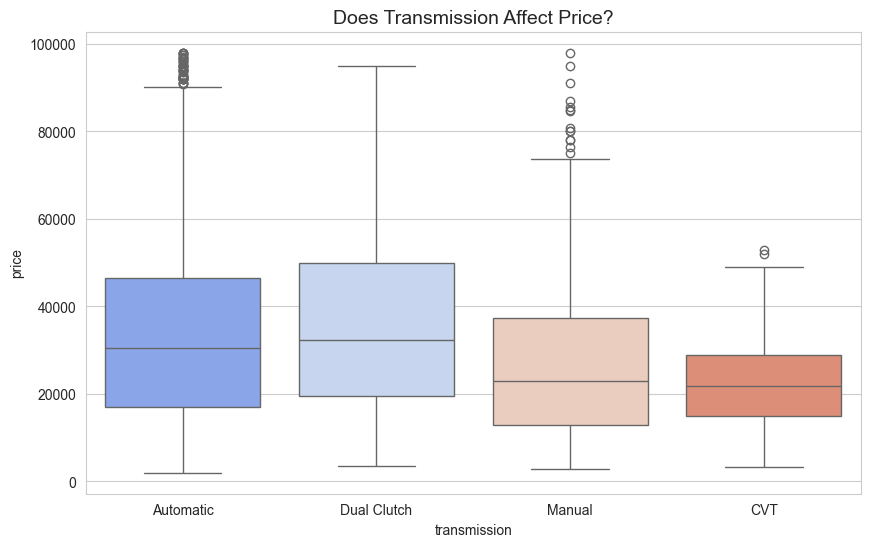

In [232]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=cars, x='transmission', y='price', palette='coolwarm')
plt.title('Does Transmission Affect Price?', fontsize=14)
plt.show()

**Fuel vs Price**

C:\Users\BerniceBoateng\AppData\Local\Temp\ipykernel_8796\2181710908.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cars, x='fuel_type', y='price', palette='Set2')


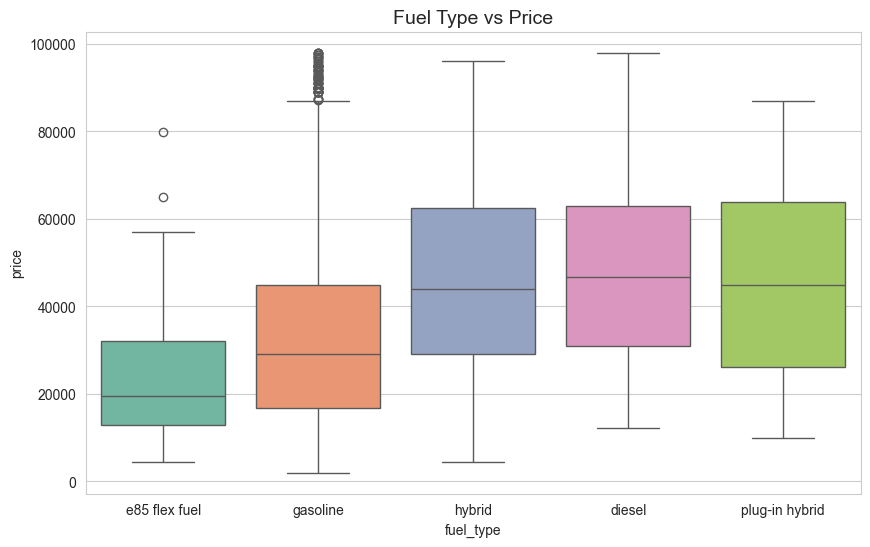

In [233]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=cars, x='fuel_type', y='price', palette='Set2')
plt.title('Fuel Type vs Price', fontsize=14)
plt.show()

**Scatter Plots(trends)**

**Year vs Price**

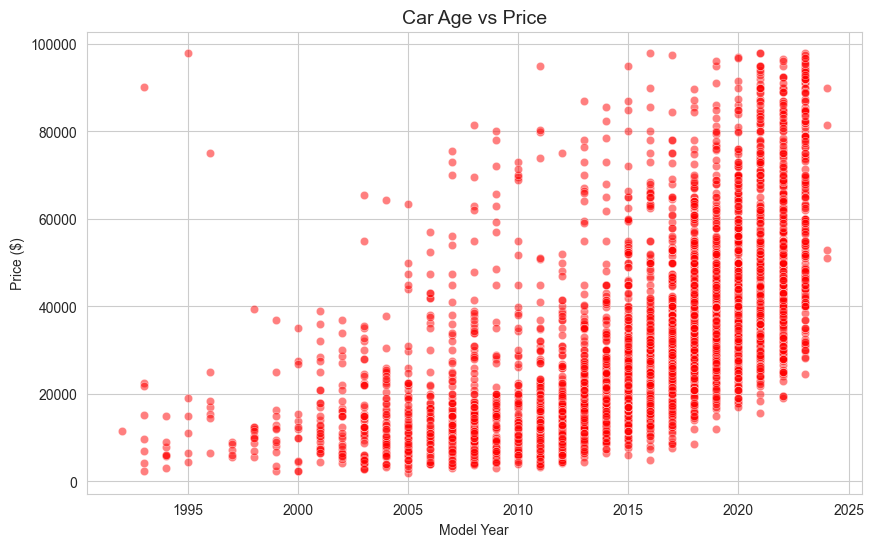

In [234]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cars, x='model_year', y='price', alpha=0.5, color='red')
plt.title('Car Age vs Price', fontsize=14)
plt.xlabel('Model Year')
plt.ylabel('Price ($)')
plt.show()

**Mileage vs Price**

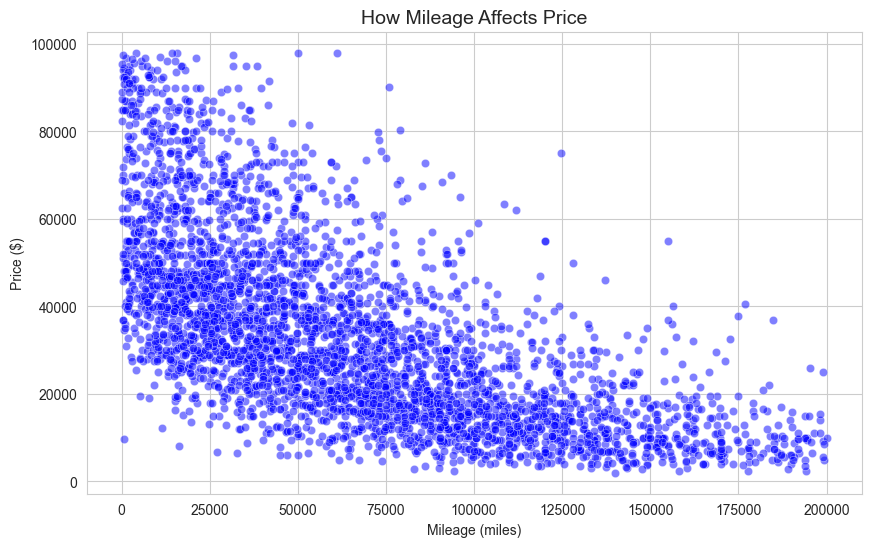

In [235]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=cars, x='mileage', y='price', alpha=0.5, color='blue')
plt.title('How Mileage Affects Price', fontsize=14)
plt.xlabel('Mileage (miles)')
plt.ylabel('Price ($)')
plt.show()
